In [5]:
import os
import os.path as op

import matplotlib.pyplot as plt

import hnn_core
from hnn_core.params import _short_name

from hnn_core import new_calcium_model, simulate_dipole, read_dipole, MPIBackend, jones_2009_model

from hnn_core.optimization import Optimizer
import numpy as np
hnn_core_root = op.join(op.dirname(hnn_core.__file__))
pathfig = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_HNN/figures/'

# The number of cores may need modifying depending on your current machine.
n_procs = 10

In [6]:
exp_dpl = read_dipole('/Users/katharinaduecker/Documents/projects_brown/hnn-data/MEG_detection_data/S1_SupraT.txt')

In [7]:

prox1_weights_ampa = {'L2_basket': 0.009355766425012867*0.5,
                        'L2_pyramidal': 0.017821964058181386*0.4,
                        'L5_basket': 0.06360458875185422*2,
                        'L5_pyramidal': 0.19529920430756656}
prox1_weights_nmda = {'L2_basket': 0.0019710468589739668*0.1,
                        'L2_pyramidal': 0.005363307709092387*0.2,
                        'L5_basket': 0.004440122026440295,
                        'L5_pyramidal': 0.11613875475625732*0.02}

dist_weights_ampa = {'L2_basket': 0.0034061998909488485*0.1,
                    'L2_pyramidal': 0.04571263358904524,
                    'L5_pyramidal': 0.03070737911180561}
dist_weights_nmda = {'L2_basket': 0.0032451182438157145,
                    'L2_pyramidal': 0.023128505130650276,
                    'L5_pyramidal': 0.23013679176569424}

prox2_weights_ampa = {'L2_basket': 0.0068621596378251855,
                        'L2_pyramidal': 0.03098179455638236,
                        'L5_basket': 0.0028128946269181136,
                        'L5_pyramidal': 0.6487065801685004}
prox2_weights_nmda = {'L2_basket': 0.009409301539150934,
                    'L2_pyramidal': 0.12711473194831402,
                    'L5_basket': 0.00028935388454280175,
                    'L5_pyramidal': 0.3419028116089666}

In [8]:
tstop = exp_dpl.times[-1]
scale_factor = 1000
smooth_window_len = 10

from hnn_core.dipole import _rmse

net_init = new_calcium_model()

synaptic_delays_p = {'L2_basket': 0.1, 'L2_pyramidal': 0.1,
                     'L5_basket': 1., 'L5_pyramidal': 1.}
net_init.add_evoked_drive('evprox1',
                        mu=16.,
                        sigma=2.3,
                        numspikes=1,
                        location='proximal',
                        weights_ampa=prox1_weights_ampa,
                        weights_nmda=prox1_weights_nmda,
                        synaptic_delays=synaptic_delays_p, event_seed=544)

# Distal
synaptic_delays_d = {'L2_basket': 0.1, 'L2_pyramidal': 0.1, 'L5_pyramidal': 1.}

net_init.add_evoked_drive('evdist',
                        mu=58.5,
                        sigma=2.5,
                        numspikes=2,
                        location='distal',
                        weights_ampa=dist_weights_ampa,
                        weights_nmda=dist_weights_nmda,
                        synaptic_delays=synaptic_delays_d, event_seed=544)

net_init.add_evoked_drive('evprox2',
                    mu=97,
                    sigma=10,
                    numspikes=6,
                    location='proximal',
                    weights_ampa=prox2_weights_ampa,
                    weights_nmda=prox2_weights_nmda,
                    synaptic_delays=synaptic_delays_p, event_seed=544)
init_dpl = simulate_dipole(net_init, tstop=tstop, n_trials=1,bsl_cor='calcium', record_vsec='all', record_isec='all')[0]

init_dpl.scale(scale_factor).smooth(smooth_window_len)

init_rmse = _rmse(init_dpl, exp_dpl,tstart=0,tstop=1000)


Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Trial 1: 150.0 ms...
Trial 1: 160.0 ms...
Trial 1: 170.0 ms...


In [10]:
import pickle
with open('optim_time.pkl', 'rb') as file:
        net_ = pickle.load(file)

In [15]:
net_.external_drives['evprox1']['weights_ampa']

{'L2_basket': 0.049215652055858136,
 'L2_pyramidal': 0.008739791084703059,
 'L5_basket': 0.07533928398974252,
 'L5_pyramidal': 0.43358890188330773}

In [16]:
net = new_calcium_model()

net.add_evoked_drive('evprox1',
                     mu = net_.external_drives['evprox1']['dynamics']['mu'],
                    sigma = net_.external_drives['evprox1']['dynamics']['sigma'],
                    numspikes = net_.external_drives['evprox1']['dynamics']['numspikes'],
                    location = 'proximal',
                    weights_ampa = net_.external_drives['evprox1']['weights_ampa'],
                    weights_nmda = net_.external_drives['evprox1']['weights_nmda'],
                    synaptic_delays = net_.external_drives['evprox1']['synaptic_delays'],
                    event_seed = 544)

net.add_evoked_drive('evdist',
                        mu = net_.external_drives['evdist']['dynamics']['mu'],
                        sigma = net_.external_drives['evdist']['dynamics']['sigma'],
                        numspikes = net_.external_drives['evdist']['dynamics']['numspikes'],
                        location = 'distal',
                        weights_ampa = net_.external_drives['evdist']['weights_ampa'],
                        weights_nmda = net_.external_drives['evdist']['weights_nmda'],
                        synaptic_delays = net_.external_drives['evdist']['synaptic_delays'],
                        event_seed = 544)

net.add_evoked_drive('evprox2', 
                    mu = net_.external_drives['evprox2']['dynamics']['mu'],
                    sigma = net_.external_drives['evprox2']['dynamics']['sigma'],
                    numspikes = net_.external_drives['evprox2']['dynamics']['numspikes'],
                    location = 'proximal',
                    weights_ampa = net_.external_drives['evprox2']['weights_ampa'],
                    weights_nmda = net_.external_drives['evprox2']['weights_nmda'],
                    synaptic_delays = net_.external_drives['evprox2']['synaptic_delays'],
                    event_seed = 544)

optim_dpl = simulate_dipole(net, tstop=tstop, n_trials=1,bsl_cor='calcium', record_vsec='all', record_isec='all')[0]
optim_dpl.scale(scale_factor).smooth(smooth_window_len)
optim_rmse = _rmse(optim_dpl, exp_dpl,tstart=0,tstop=1000)

Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Trial 1: 150.0 ms...
Trial 1: 160.0 ms...
Trial 1: 170.0 ms...


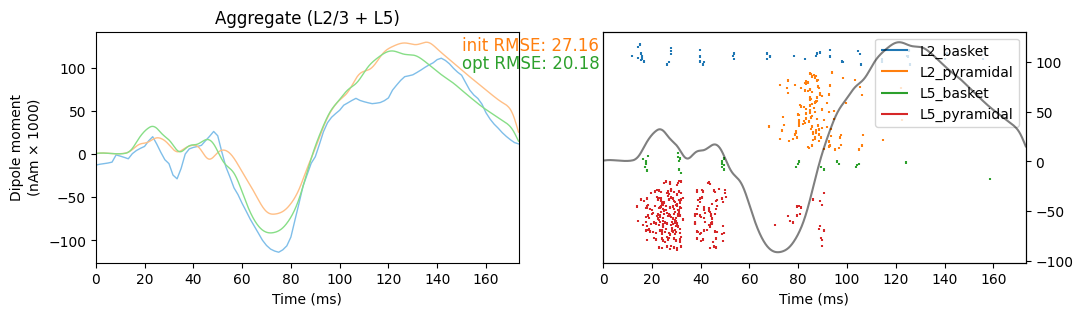

In [17]:
fig, axes = plt.subplots(1,2,figsize=(12, 3), sharex=True)

# plot original
exp_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:blue')
init_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:orange')
axes[0].text(150,120, f'init RMSE: {init_rmse:.2f}', fontsize=12, color='tab:orange')
optim_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:green')
axes[0].text(150,100, f'opt RMSE: {optim_rmse:.2f}', fontsize=12, color='tab:green')

net.cell_response.plot_spikes_raster(ax=axes[1], show=False)
ax2 = axes[1].twinx()
ax2.plot(optim_dpl.times,optim_dpl.data['agg'],color='k', alpha=0.5)